# 02 · Mixture of Factor Analyzers — EM and BIC selection
Custom NumPy implementation in `src/mfa.py`; low-rank algebra in `src/woodbury.py`.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

## Woodbury identity check

In [2]:
from src.woodbury import WoodburyFactor
rng = np.random.default_rng(0); d, r = 384, 16
f = WoodburyFactor.build(rng.normal(size=d), rng.normal(size=(d, r))*.05, rng.uniform(1e-3, 3e-3, d))
S = f.W @ f.W.T + np.diag(f.psi)
print('max |Woodbury - inv| =', np.abs(f.precision() - np.linalg.inv(S)).max())
print('logdet error =', abs(f.log_det - np.linalg.slogdet(S)[1]))

max |Woodbury - inv| = 3.6500580335996347e-11


logdet error = 9.094947017729282e-13


## Fit one MFA live (K = 8, r = 16) on training passages

In [3]:
from src.mfa import MFA
split = np.load('data/train_val_split.npz')
X = np.load('data/corpus_embeddings.npy').astype(float)
Xtr = X[split['train_idx']]
m = MFA(8, 16, verbose=True).fit(Xtr)
print(f'{m.n_iter_} iterations, converged={m.converged_}, {m.fit_time_:.1f}s, params={m.n_parameters():,}')
print('full-cov GMM params would be', 8*(384*385//2 + 384) + 7)

  iter   1  logL = 32,735,629.44


  iter   2  logL = 32,815,072.88


  iter   3  logL = 32,849,367.07


  iter   4  logL = 32,875,146.63


  iter   5  logL = 32,894,023.53


  iter   6  logL = 32,909,138.18


... (41 outputs left out)

  iter  48  logL = 33,005,832.45


  iter  49  logL = 33,006,412.77


  iter  50  logL = 33,006,859.15


50 iterations, converged=False, 135.9s, params=54,343
full-cov GMM params would be 594439


## BIC grid (K × r)

In [4]:
bic = pd.read_csv('results/bic_grid.csv'); bic.round(1)

,source,K,r,log_likelihood,n_params,BIC,iterations,converged,fit_seconds
0,passage,2,8,30799842.0,7625,-61518448.5,19,True,148.7
1,passage,2,16,31729542.6,13585,-63314352.8,22,True,159.6
2,passage,2,32,32848283.1,25121,-65428931.0,22,True,175.5
3,passage,2,64,34192310.3,46657,-67887544.2,27,True,166.3
4,passage,4,8,31292243.0,15251,-62422004.3,32,True,72.0
5,passage,4,16,32302343.0,27171,-64315210.4,33,True,79.2
6,passage,4,32,33521070.9,50243,-66506860.9,50,False,87.6
7,passage,4,64,34968931.3,93315,-68943699.4,42,True,130.5
8,passage,8,8,31925606.3,30503,-63526238.4,50,False,139.8
9,passage,8,16,33007260.0,54343,-65435558.2,50,False,148.6


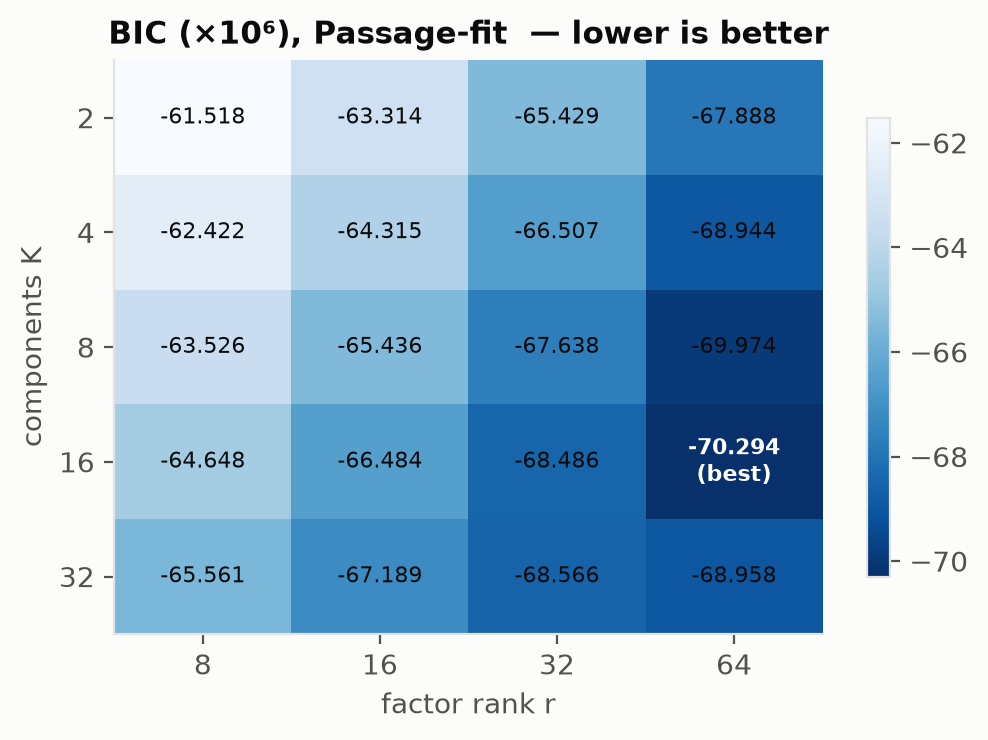

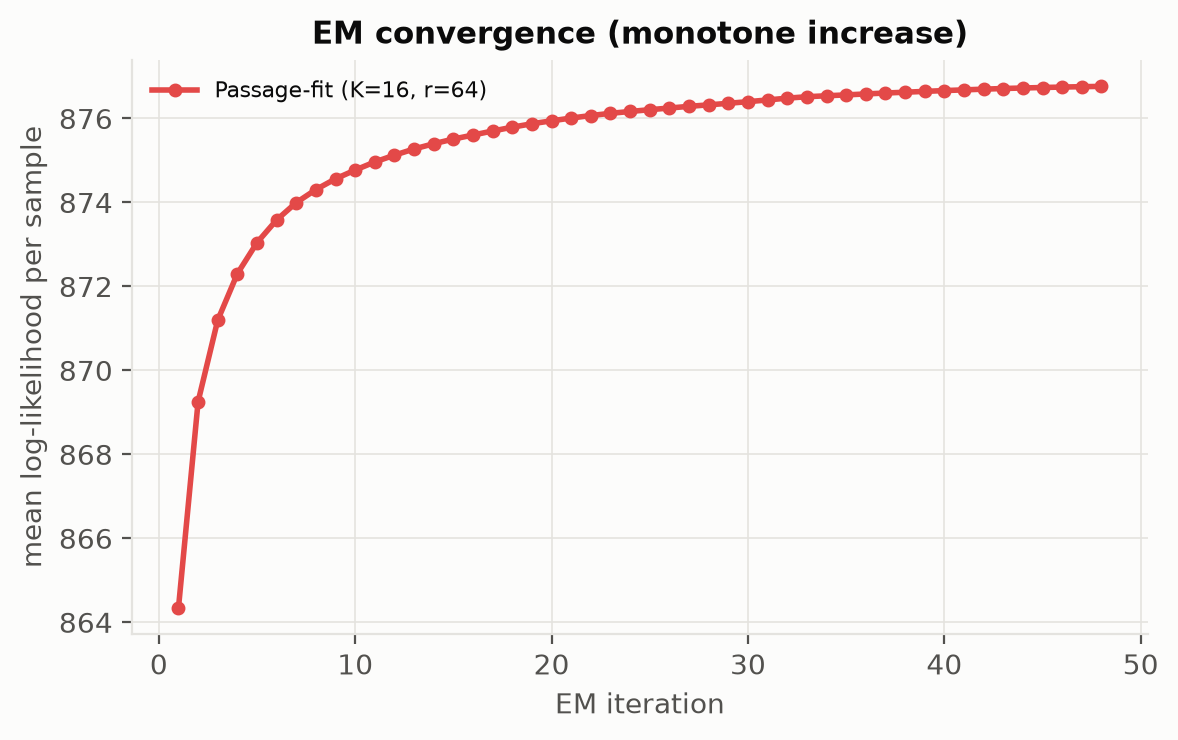

In [5]:
display(Image('results/bic_heatmap.png'))
display(Image('results/em_loglik.png'))

In [6]:
json.load(open('results/summary.json'))['sources']

{'passage': {'K': 16,
  'r': 64,
  'n_train': 42355,
  'n_val': 10588,
  'mfa_params': 373263,
  'full_gmm_params': 1188879,
  'evt': {'tau0': 483.096190783861,
   'kappa': 1.0528628834162568,
   'lambda': 50.854198312049434,
   'ks_pvalue': 0.5698083166404753,
   'threshold_at_alpha': 700.0023022987833},
  'em_iterations': 48,
  'em_converged': True}}